# Перенос обучения + fine tuning
Берем предобученную модель и дообучаем на новом наборе данных с маленьким шагом обучения

In [1]:
import os
import json
import time
from datetime import datetime, timedelta
from pathlib import Path
import shutil

import yaml
import cv2
import numpy as np
import albumentations as A
import torch
from PIL import Image, ImageDraw, ImageFont

import sys

repo_path = Path("/home/himoza/block_detect/ultralytics")

sys.path.insert(0, str(repo_path))

from ultralytics import YOLO

/home/himoza/miniconda3/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Функция валидации

In [2]:
def validate_model(model_path, data_yaml, split="val"):
    """
    Отдельная функция валидации модели
    """

    print(f"\nVALIDATING: {model_path}\n")

    model = YOLO(model_path)

    metrics = model.val(
        data=data_yaml,
        split=split,
        verbose=True
    )

    results = {
        "mAP50": metrics.box.map50,
        "mAP50-95": metrics.box.map,
        "precision": metrics.box.mp,
        "recall": metrics.box.mr
    }

    print("\nValidation Metrics:")
    for k, v in results.items():
        print(f"{k}: {v:.4f}")

    return results

## Функция обучения

In [33]:
def format_time(seconds):
    """
    Красивое форматирование времени
    """

    hours = int(seconds // 3600)
    minutes = int((seconds % 3600) // 60)
    secs = int(seconds % 60)

    return f"{hours:02d}:{minutes:02d}:{secs:02d}"

In [34]:
def train_two_stage_yolo(
    data_yaml,
    project_name,
    pretrained_weights="yolov8m.pt",
    output_dir="training_results",
    imgsz=640,
    batch=16,

    # Stage 1
    stage1_epochs=150,
    stage1_freeze=10,
    stage1_lr=1e-3,

    # Stage 2
    stage2_epochs=150,
    stage2_lr=1e-4,

    # Early stopping
    patience=20,

    device=0,

    custom_augmentations=None,
    
    coverage_lambda=0.5,
    
    seed=42
):
    """
    Двухэтапное обучение YOLO:
    1. Frozen backbone training
    2. Full fine-tuning
    """
    # TOTAL TIMER

    total_start_time = time.time()

    output_dir = Path(output_dir)
    output_dir.mkdir(exist_ok=True)

    # STAGE 1

    print("\n" + "=" * 60)
    print("STAGE 1: TRAIN HEAD WITH FROZEN BACKBONE")
    print("=" * 60)

    stage1_start_time = time.time()

    model = YOLO(pretrained_weights)

    stage1_project = os.path.abspath(os.path.join(output_dir, project_name, 'stage1'))

    model.train(
        data=data_yaml,

        epochs=stage1_epochs,

        imgsz=imgsz,
        batch=batch,

        freeze=stage1_freeze,

        optimizer="AdamW",
        lr0=stage1_lr,

        cos_lr=True,
        lrf=0.1,

        patience=patience,

        project=str(stage1_project),
        name="train",

        device=device,

        save=True,
        save_period=20,

        verbose=True,
        augmentations=custom_augmentations,
        mosaic=0.5,
        
        coverage_lambda=coverage_lambda,
        
        seed=seed,
        deterministic=True
    )

    # STAGE 1 TIME

    stage1_training_time = time.time() - stage1_start_time

    print("\n" + "=" * 60)
    print(f"STAGE 1 TRAINING TIME: {format_time(stage1_training_time)}")
    print("=" * 60)

    # BEST MODEL STAGE 1

    best_stage1 = os.path.join(stage1_project, "train", "weights", "best.pt")

    print(f"\nBest Stage 1 Model: {best_stage1}")

    # VALIDATION AFTER STAGE 1

    print("\n" + "=" * 60)
    print("VALIDATION AFTER STAGE 1")
    print("=" * 60)

    stage1_validation_start = time.time()

    stage1_metrics = validate_model(
        model_path=str(best_stage1),
        data_yaml=data_yaml
    )

    stage1_validation_time = time.time() - stage1_validation_start

    print(
        f"\nStage 1 Validation Time: "
        f"{format_time(stage1_validation_time)}"
    )

    # STAGE 2

    print("\n" + "=" * 60)
    print("STAGE 2: FULL FINE-TUNING")
    print("=" * 60)

    stage2_start_time = time.time()

    model_stage2 = YOLO(str(best_stage1))

    stage2_project = os.path.abspath(os.path.join(output_dir, project_name, 'stage2'))

    model_stage2.train(
        data=data_yaml,

        epochs=stage2_epochs,

        imgsz=imgsz,
        batch=batch,

        freeze=None,

        optimizer="AdamW",
        lr0=stage2_lr,

        cos_lr=True,
        lrf=0.1,

        patience=patience,

        project=str(stage2_project),
        name="train",

        device=device,

        save=True,
        save_period=20,

        verbose=True,
        augmentations=custom_augmentations,
        mosaic=0.5,
        
        coverage_lambda=coverage_lambda,
        seed=seed,
        deterministic=True
    )

    # STAGE 2 TIME

    stage2_training_time = time.time() - stage2_start_time

    print("\n" + "=" * 60)
    print(f"STAGE 2 TRAINING TIME: {format_time(stage2_training_time)}")
    print("=" * 60)

    # BEST MODEL STAGE 2
    best_stage2 = os.path.join(stage2_project, "train", "weights", "best.pt")

    print(f"\nBest Stage 2 Model: {best_stage2}")

    # FINAL VALIDATION

    print("\n" + "=" * 60)
    print("FINAL VALIDATION")
    print("=" * 60)

    final_validation_start = time.time()

    final_metrics = validate_model(
        model_path=str(best_stage2),
        data_yaml=data_yaml
    )

    final_validation_time = time.time() - final_validation_start

    print(
        f"\nFinal Validation Time: "
        f"{format_time(final_validation_time)}"
    )

    # COPY FINAL MODEL

    final_model_path = os.path.join(output_dir, project_name, "best_final_model.pt")

    shutil.copy(best_stage2, final_model_path)

    print(f"\nFinal model saved to: {final_model_path}")

    # TOTAL TIME

    total_training_time = time.time() - total_start_time

    print("\n" + "=" * 60)
    print("TOTAL TRAINING SUMMARY")
    print("=" * 60)

    print(f"Stage 1 Training Time : {format_time(stage1_training_time)}")
    print(f"Stage 1 Validation Time: {format_time(stage1_validation_time)}")

    print(f"Stage 2 Training Time : {format_time(stage2_training_time)}")
    print(f"Final Validation Time : {format_time(final_validation_time)}")

    print(f"\nTOTAL PIPELINE TIME: {format_time(total_training_time)}")

    print("=" * 60)

    # RETURN RESULTS

    results = {
        "stage1_best_model": str(best_stage1),
        "stage2_best_model": str(best_stage2),
        "final_model": str(final_model_path),

        "stage1_metrics": stage1_metrics,
        "final_metrics": final_metrics,

        "timing": {
            "stage1_training_time_sec": stage1_training_time,
            "stage1_validation_time_sec": stage1_validation_time,
            "stage2_training_time_sec": stage2_training_time,
            "final_validation_time_sec": final_validation_time,
            "total_pipeline_time_sec": total_training_time,

            "stage1_training_time_str": format_time(stage1_training_time),
            "stage1_validation_time_str": format_time(stage1_validation_time),
            "stage2_training_time_str": format_time(stage2_training_time),
            "final_validation_time_str": format_time(final_validation_time),
            "total_pipeline_time_str": format_time(total_training_time)
        }
    }

    return results

## Функция сопоставления предсказания YOLO с ground truth разметкой

In [ ]:
def visualize_predictions_vs_gt(
    project_name,
    results_dir,
    data_yaml_path,
    num_samples=20,
    conf_threshold=0.25,
    iou_threshold=0.45,
    img_size=640,
    seed=42
):
    """
    Создает изображения сравнения ground truth и предсказаний YOLO

    Args:
        project_name: имя проекта
        results_dir: путь к результату
        data_yaml_path: путь к data.yaml с информацией о датасете
        num_samples: количество изображений для визуализации
        conf_threshold: порог уверенности для предсказаний
        iou_threshold: порог IoU для NMS
        img_size: размер изображения для модели
        seed: random seed для воспроизводимости
    """
    full_project_path = os.path.join(results_dir, project_name)
    best_model_path = os.path.join(full_project_path, 'stage2', 'train', 'weights', 'best.pt')
    output_dir = os.path.join(full_project_path, 'val', 'res')
    # Создаем выходную директорию
    os.makedirs(output_dir, exist_ok=True)

    # Загружаем модель
    model = YOLO(best_model_path)

    # Загружаем конфигурацию датасета
    with open(data_yaml_path, 'r') as f:
        data_config = yaml.safe_load(f)

    class_names = data_config['names']
    num_classes = len(class_names)

    # Генерируем цвета для классов (фиксированные для воспроизводимости)
    np.random.seed(42)
    colors = np.random.randint(0, 255, size=(num_classes, 3), dtype=np.uint8)

    # Загружаем список изображений из валидационного сета
    val_images_dir = data_config.get('val', data_config.get('valid'))[3:]

    if val_images_dir is None:
        raise ValueError("Не найден путь к валидационным изображениям в data.yaml")

    # Получаем список изображений
    if os.path.isabs(val_images_dir):
        val_path = Path(val_images_dir)
    else:
        val_path = Path(data_yaml_path).parent / val_images_dir

    image_files = []
    for ext in ['*.jpg', '*.jpeg', '*.png', '*.bmp']:
        image_files.extend(list(val_path.glob(ext)))

    print(val_path)
    if len(image_files) == 0:
        raise ValueError(f"Не найдены изображения в {val_path}")

    # Случайно выбираем num_samples изображений
    np.random.seed(seed)
    selected_images = np.random.choice(image_files,
                                       size=min(num_samples, len(image_files)),
                                       replace=False)

    # Функция для отрисовки боксов (GT или предсказания)
    def draw_boxes(img, boxes, labels=None, confidences=None, is_pred=False):
        """
        Рисует bounding boxes на изображении
        """
        img_copy = img.copy()
        h, w = img_copy.shape[:2]

        for i, box in enumerate(boxes):
            # Конвертируем нормализованные координаты в пиксельные
            if max(box) <= 1.0:  # если координаты нормализованы
                x1, y1, x2, y2 = box
                x1, y1 = int(x1 * w), int(y1 * h)
                x2, y2 = int(x2 * w), int(y2 * h)
            else:
                x1, y1, x2, y2 = map(int, box)

            # Определяем цвет и параметры
            if is_pred:
                # Для предсказаний используем цвет класса и пунктир
                if labels is not None and i < len(labels):
                    class_id = int(labels[i])
                    color = tuple(map(int, colors[class_id % len(colors)]))
                else:
                    color = (0, 255, 0)  # зеленый по умолчанию

                thickness = 2
                line_type = cv2.LINE_AA

                # Рисуем прямоугольник
                cv2.rectangle(img_copy, (x1, y1), (x2, y2), color, thickness, line_type)

                # Добавляем подпись с классом и уверенностью
                if labels is not None and i < len(labels):
                    class_id = int(labels[i])
                    class_name = class_names[class_id] if class_id < len(class_names) else f"Class {class_id}"

                    conf_str = ""
                    if confidences is not None and i < len(confidences):
                        conf_str = f" {confidences[i]:.2f}"

                    label_text = f"{class_name}{conf_str}"

                    # Рисуем фон для текста
                    (text_w, text_h), _ = cv2.getTextSize(label_text, cv2.FONT_HERSHEY_SIMPLEX, 0.5, 2)
                    cv2.rectangle(img_copy, (x1, y1 - text_h - 5), (x1 + text_w, y1), color, -1)
                    cv2.putText(img_copy, label_text, (x1, y1 - 3),
                              cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 2, cv2.LINE_AA)
            else:
                # Для GT используем синий цвет и сплошную линию
                color = (255, 0, 0)  # синий для GT
                thickness = 2
                line_type = cv2.LINE_AA

                cv2.rectangle(img_copy, (x1, y1), (x2, y2), color, thickness, line_type)

                # Добавляем подпись класса для GT
                if labels is not None and i < len(labels):
                    class_id = int(labels[i])
                    class_name = class_names[class_id] if class_id < len(class_names) else f"Class {class_id}"

                    label_text = class_name
                    (text_w, text_h), _ = cv2.getTextSize(label_text, cv2.FONT_HERSHEY_SIMPLEX, 0.5, 2)
                    cv2.rectangle(img_copy, (x1, y1 - text_h - 5), (x1 + text_w, y1), color, -1)
                    cv2.putText(img_copy, label_text, (x1, y1 - 3),
                              cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 2, cv2.LINE_AA)

        return img_copy

    # Обрабатываем каждое изображение
    for idx, img_path in enumerate(selected_images):
        print(f"Обработка {idx+1}/{len(selected_images)}: {img_path.name}")

        # Загружаем изображение
        img = cv2.imread(str(img_path))
        if img is None:
            print(f"Не удалось загрузить изображение: {img_path}")
            continue

        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        # === Получаем Ground Truth ===
        # Ищем соответствующий label файл
        label_path = None
        possible_label_dirs = [
            val_path.parent / 'labels' / val_path.name,  # если labels/val
            Path(data_config.get('labels', '')) / val_path.name if data_config.get('labels') else None,
            val_path.parent / 'labels'  # если labels в той же папке
        ]

        for label_dir in possible_label_dirs:
            if label_dir is not None and label_dir.exists():
                potential_label = label_dir / f"{img_path.stem}.txt"
                if potential_label.exists():
                    label_path = potential_label
                    break

        # Если не нашли в стандартных местах, ищем рядом с изображением
        if label_path is None:
            potential_label = img_path.parent / f"{img_path.stem}.txt"
            if potential_label.exists():
                label_path = potential_label

        gt_boxes = []
        gt_labels = []

        if label_path and label_path.exists():
            with open(label_path, 'r') as f:
                for line in f.readlines():
                    parts = line.strip().split()
                    if len(parts) >= 5:
                        class_id = int(parts[0])
                        # YOLO формат: class_id cx cy w h (все нормализовано)
                        cx, cy, bw, bh = map(float, parts[1:5])
                        x1 = cx - bw / 2
                        y1 = cy - bh / 2
                        x2 = cx + bw / 2
                        y2 = cy + bh / 2

                        gt_boxes.append([x1, y1, x2, y2])
                        gt_labels.append(class_id)

        # === Получаем предсказания ===
        results = model.predict(
            str(img_path),
            conf=conf_threshold,
            iou=iou_threshold,
            imgsz=img_size,
            verbose=False
        )

        pred_boxes = []
        pred_labels = []
        pred_confs = []

        if len(results) > 0 and results[0].boxes is not None:
            boxes = results[0].boxes

            if len(boxes) > 0:
                # Получаем координаты в формате xyxy
                xyxy_boxes = boxes.xyxy.cpu().numpy()
                class_ids = boxes.cls.cpu().numpy()
                confidences = boxes.conf.cpu().numpy()

                # Нормализуем координаты
                h, w = img.shape[:2]
                normalized_boxes = []
                for box in xyxy_boxes:
                    x1, y1, x2, y2 = box
                    normalized_boxes.append([x1/w, y1/h, x2/w, y2/h])

                pred_boxes = normalized_boxes
                pred_labels = class_ids.tolist()
                pred_confs = confidences.tolist()

        # === Создаем изображения с аннотациями ===
        gt_img = draw_boxes(img_rgb, gt_boxes, gt_labels, is_pred=False)
        pred_img = draw_boxes(img_rgb, pred_boxes, pred_labels, pred_confs, is_pred=True)

        # === Объединяем изображения side-by-side ===
        # Добавляем заголовки
        gt_img_pil = Image.fromarray(gt_img)
        pred_img_pil = Image.fromarray(pred_img)

        # Создаем объединенное изображение
        total_width = gt_img_pil.width + pred_img_pil.width
        max_height = max(gt_img_pil.height, pred_img_pil.height) + 40  # +40 для заголовка

        combined_img = Image.new('RGB', (total_width, max_height), color=(255, 255, 255))

        # Вставляем изображения
        combined_img.paste(gt_img_pil, (0, 40))
        combined_img.paste(pred_img_pil, (gt_img_pil.width, 40))

        # Добавляем текст заголовков
        draw = ImageDraw.Draw(combined_img)

        try:
            # Пытаемся использовать системный шрифт
            font = ImageFont.truetype("/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf", 20)
        except:
            # Если шрифт не найден, используем стандартный
            font = ImageFont.load_default()

        # Заголовки
        draw.text((10, 10), "Ground Truth", fill=(255, 0, 0), font=font)
        draw.text((gt_img_pil.width + 10, 10), "Predictions", fill=(0, 255, 0), font=font)

        # Дополнительная информация: название файла и статистика
        stats_text = f"File: {img_path.name} | GT objects: {len(gt_boxes)} | Pred objects: {len(pred_boxes)}"
        draw.text((10, max_height - 25), stats_text, fill=(0, 0, 0), font=ImageFont.load_default())

        # Сохраняем результат
        output_filename = f"comparison_{idx+1:03d}_{img_path.stem}.jpg"
        output_path = os.path.join(output_dir, output_filename)
        combined_img.save(output_path, quality=95)

        print(f"  Сохранено: {output_filename}")
        print(f"  GT: {len(gt_boxes)} объектов, Predictions: {len(pred_boxes)} объектов")
        print()

    print(f"\n✅ Готово! Все изображения сохранены в: {output_dir}")
    print(f"Всего обработано изображений: {len(selected_images)}")

    return output_dir

## Функции оценки метрики Intersection / GT

In [13]:
def box_area(box):
    x1, y1, x2, y2 = box

    return max(0, x2 - x1) * max(0, y2 - y1)


def intersection_area(box1, box2):

    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    return (
        max(0, x2 - x1) *
        max(0, y2 - y1)
    )


def intersection_over_gt(pred_box, gt_box):

    intersection = intersection_area(
        pred_box,
        gt_box
    )

    gt_area = box_area(gt_box)

    if gt_area == 0:
        return 0.0

    return intersection / gt_area


def iou(box1, box2):

    intersection = intersection_area(box1, box2)

    area1 = box_area(box1)
    area2 = box_area(box2)

    union = area1 + area2 - intersection

    if union == 0:
        return 0.0

    return intersection / union


def yolo_to_xyxy(label, img_width, img_height):

    cls, xc, yc, w, h = label

    xc *= img_width
    yc *= img_height
    w *= img_width
    h *= img_height

    x1 = xc - w / 2
    y1 = yc - h / 2
    x2 = xc + w / 2
    y2 = yc + h / 2

    return [x1, y1, x2, y2], int(cls)

In [14]:
def evaluate_image(
    model,
    image_path,
    label_path,
    matching_iou_threshold=0.1
):

    # Prediction

    results = model(
        str(image_path),
        verbose=False
    )

    result = results[0]

    img_height, img_width = result.orig_shape

    pred_boxes = result.boxes.xyxy.cpu().numpy()
    pred_classes = result.boxes.cls.cpu().numpy().astype(int)

    # Ground Truth

    gt_boxes = []
    gt_classes = []

    if label_path.exists():

        with open(label_path, "r") as f:

            for line in f:

                values = list(
                    map(float, line.strip().split())
                )

                box, cls = yolo_to_xyxy(
                    values,
                    img_width,
                    img_height
                )

                gt_boxes.append(box)
                gt_classes.append(cls)

    # Matching

    matches = []

    used_predictions = set()

    for gt_idx, (gt_box, gt_class) in enumerate(
        zip(gt_boxes, gt_classes)
    ):

        best_iou = 0.0
        best_pred_idx = None

        for pred_idx, (pred_box, pred_class) in enumerate(
            zip(pred_boxes, pred_classes)
        ):

            if pred_idx in used_predictions:
                continue

            # Класс должен совпадать
            if pred_class != gt_class:
                continue

            current_iou = iou(
                pred_box,
                gt_box
            )

            if current_iou > best_iou:

                best_iou = current_iou
                best_pred_idx = pred_idx

        if (
            best_pred_idx is not None
            and best_iou >= matching_iou_threshold
        ):

            used_predictions.add(best_pred_idx)

            pred_box = pred_boxes[best_pred_idx]

            custom_score = intersection_over_gt(
                pred_box,
                gt_box
            )

            matches.append({
                "gt_idx": gt_idx,
                "pred_idx": best_pred_idx,
                "class": gt_class,
                "iou": best_iou,
                "intersection_gt": custom_score
            })

    scores = [
        match["intersection_gt"]
        for match in matches
    ]

    if len(scores) > 0:
        image_metric = np.mean(scores)
    else:
        image_metric = None

    return image_metric, matches

## Конфигурация

In [6]:
RESULTS_DIR = "./train_result_new_data"
os.makedirs(RESULTS_DIR, exist_ok=True)

DATA_YAML = "./new_block_detection-2/data.yaml"

DEVICE = 0 if torch.cuda.is_available() else 'cpu'

EPOCHS = 200
IMGSZ = 640
PATIENCE = 10          # Early stopping: остановка через 10 эпох без улучшения
BATCH_SIZE = 32

## Предобученная модель yolov8n

### Обучение

In [23]:
pretrained_weights = './train_result/yolov8n_training/train/weights/best.pt'
project_name = "yolov8n_transfer_learning_new_loss"

In [24]:
results = train_two_stage_yolo(
    data_yaml=DATA_YAML,
    project_name=project_name,
    pretrained_weights=pretrained_weights,

    output_dir=RESULTS_DIR,

    imgsz=640,
    batch=BATCH_SIZE,

    stage1_epochs=200,
    stage1_freeze=10,
    stage1_lr=1e-4,

    stage2_epochs=200,
    stage2_lr=1e-5,

    patience=PATIENCE,

    device=DEVICE,
    coverage_lambda=10
)


STAGE 1: TRAIN HEAD WITH FROZEN BACKBONE
Ultralytics 8.4.175 🚀 Python-3.13.9 torch-2.12.0+cu130 CUDA:0 (NVIDIA GeForce RTX 2060, 5730MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, augmentations=None, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, coverage_lambda=10, cutmix=0.0, data=./new_block_detection-2/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=200, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.1, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=./train_result/yolov8n_

### Визуализация на новом наборе данных

In [25]:
visualize_predictions_vs_gt(
    project_name,
    RESULTS_DIR,
    DATA_YAML,
    num_samples=400,
    conf_threshold=0.3,
    iou_threshold=0.4,
    img_size=640,
    seed=42
)

new_block_detection-2/valid/images
Обработка 1/11: vid0499img1290_1_0_jpg.rf.59b9909ce55a9c1e8168e2d1ee2692f1.jpg
  Сохранено: comparison_001_vid0499img1290_1_0_jpg.rf.59b9909ce55a9c1e8168e2d1ee2692f1.jpg
  GT: 5 объектов, Predictions: 12 объектов

Обработка 2/11: vid0489img30_4_1_jpg.rf.aca42f6e41026a1b4bd32ef6a78d28c5.jpg
  Сохранено: comparison_002_vid0489img30_4_1_jpg.rf.aca42f6e41026a1b4bd32ef6a78d28c5.jpg
  GT: 36 объектов, Predictions: 64 объектов

Обработка 3/11: vid0489img2250_4_0_jpg.rf.453d246b437d688264d264b99e30a23b.jpg
  Сохранено: comparison_003_vid0489img2250_4_0_jpg.rf.453d246b437d688264d264b99e30a23b.jpg
  GT: 18 объектов, Predictions: 31 объектов

Обработка 4/11: vid0489img30_4_0_jpg.rf.5c211fe4579a2f8d27f91d5753fb1398.jpg
  Сохранено: comparison_004_vid0489img30_4_0_jpg.rf.5c211fe4579a2f8d27f91d5753fb1398.jpg
  GT: 28 объектов, Predictions: 54 объектов

Обработка 5/11: vid0499img1200_3_0_jpg.rf.9972bb714676db1a9d62d8f25325476b.jpg
  Сохранено: comparison_005_vid0499

'./train_result_new_data/yolov8n_transfer_learning_new_loss/val/res'

In [26]:
model = YOLO("./train_result_new_data/yolov8n_transfer_learning_new_loss/best_final_model.pt")

images_dir = Path("./new_block_detection-2/valid/images")
labels_dir = Path("./new_block_detection-2/valid/labels")

all_scores = []

for image_path in images_dir.glob("*"):

    label_path = labels_dir / f"{image_path.stem}.txt"

    image_metric, matches = evaluate_image(
        model,
        image_path,
        label_path,
        matching_iou_threshold=0.3
    )

    # Если на изображении не было ни одного
    # сопоставленного объекта — пропускаем его
    if image_metric is None:
        continue

    all_scores.extend(
        match["intersection_gt"]
        for match in matches
    )

    print(
        f"{image_path.name}: "
        f"{image_metric:.4f} "
        f"объектов: {len(matches)}"
    )


# --------------------------------
# Общая метрика
# --------------------------------

if len(all_scores) > 0:

    final_metric = np.mean(all_scores)

    print("\n==============================")
    print(
        f"Intersection / GT: "
        f"{final_metric:.4f}"
    )
    print(
        f"Количество объектов: "
        f"{len(all_scores)}"
    )
    print("==============================")

else:

    print("Нет сопоставленных объектов.")

vid0489img30_4_1_jpg.rf.aca42f6e41026a1b4bd32ef6a78d28c5.jpg: 0.9810 объектов: 36
vid0493img330_3_2_jpg.rf.9b32fb16517572340e510438f4a2b700.jpg: 0.9622 объектов: 27
vid0499img1200_3_0_jpg.rf.9972bb714676db1a9d62d8f25325476b.jpg: 0.9312 объектов: 10
vid0499img1380_4_1_jpg.rf.7ac56021fb5d32f299ee02e2f3f942e4.jpg: 0.8250 объектов: 8
vid0489img2280_1_2_jpg.rf.3f1bd4eae4d057439a2f91baf1de3333.jpg: 0.9600 объектов: 36
vid0499img1290_1_0_jpg.rf.59b9909ce55a9c1e8168e2d1ee2692f1.jpg: 0.7821 объектов: 5
vid0498img1110_4_2_jpg.rf.655393520c50bf01898d6ed9653a076c.jpg: 0.9903 объектов: 15
vid0498img30_4_2_jpg.rf.285af3e44d3400585ee7668aace70aad.jpg: 0.9934 объектов: 3
vid0489img2250_2_1_jpg.rf.06985a295a14e641f58c90652bc17b55.jpg: 0.9878 объектов: 32
vid0489img2250_4_0_jpg.rf.453d246b437d688264d264b99e30a23b.jpg: 0.9812 объектов: 18
vid0489img30_4_0_jpg.rf.5c211fe4579a2f8d27f91d5753fb1398.jpg: 0.9872 объектов: 28

Intersection / GT: 0.9653
Количество объектов: 218


### Валидация на нашей метрике Intersection / Ground Truth на старом наборе данных

In [27]:
model = YOLO("./train_result_new_data/yolov8n_transfer_learning_new_loss/best_final_model.pt")

images_dir = Path("./block-detection-1/valid/images")
labels_dir = Path("./block-detection-1/valid/labels")

all_scores = []

for image_path in images_dir.glob("*"):

    label_path = labels_dir / f"{image_path.stem}.txt"

    image_metric, matches = evaluate_image(
        model,
        image_path,
        label_path,
        matching_iou_threshold=0.3
    )

    # Если на изображении не было ни одного
    # сопоставленного объекта — пропускаем его
    if image_metric is None:
        continue

    all_scores.extend(
        match["intersection_gt"]
        for match in matches
    )

    print(
        f"{image_path.name}: "
        f"{image_metric:.4f} "
        f"объектов: {len(matches)}"
    )


# --------------------------------
# Общая метрика
# --------------------------------

if len(all_scores) > 0:

    final_metric = np.mean(all_scores)

    print("\n==============================")
    print(
        f"Intersection / GT: "
        f"{final_metric:.4f}"
    )
    print(
        f"Количество объектов: "
        f"{len(all_scores)}"
    )
    print("==============================")

else:

    print("Нет сопоставленных объектов.")

many-stack-brick-background-construction-site-69549698_jpg.rf.2c1d4a0251603f35b6e7241f23e36a28.jpg: 0.9964 объектов: 133
vandersanden-kirpich-ruchnoy-formovki-oud-kapelle-m50-190-90-50-1_0001_w500_h500_watermark-2-_jpg.rf.8c61c216f6a48614049e8bea63053d13.jpg: 0.9999 объектов: 48
stack-bricks-red-construction-36132343_jpg.rf.a3ab585f8df68d8aa172d0b98a9d0ab1.jpg: 0.9611 объектов: 48
brick2-17-_jpg.rf.f64be790718963275d995fa4b939e546.jpg: 0.9903 объектов: 88
_barhat-2-500x500-500x500_jpg.rf.0ac56ded39cc32563a75454ad8649138.jpg: 0.9998 объектов: 28
383_jpg.rf.bbc945440a6bb651e33008744c19bcd2.jpg: 0.8808 объектов: 27
4-1-_jpg.rf.38692d9e8160c842930d08b826f87182.jpg: 0.9995 объектов: 104
full_4404479-0-1-_jpg.rf.3fffd358b0471fd970c05ddeac0945e5.jpg: 0.9941 объектов: 42
stack-bricks-construction-territory-near-future-house-72727138_jpg.rf.4dcad82f85499f905a9cf3aa286f0c44.jpg: 0.9804 объектов: 54
unnamed_jpg.rf.2843209a631061453c3a09b086990059.jpg: 0.9990 объектов: 35
stack-old-red-bricks-text

## Влияние coverage_lambda на целевые метрики

In [31]:
import yaml
import numpy as np
from pathlib import Path
from ultralytics import YOLO


import yaml
from pathlib import Path


def get_validation_paths(data_yaml):
    data_yaml = Path(data_yaml).resolve()

    with open(data_yaml, "r", encoding="utf-8") as f:
        config = yaml.safe_load(f)

    val = config.get("val", config.get("valid"))

    if not val:
        raise ValueError(
            f"В {data_yaml} отсутствует параметр val или valid."
        )

    val_path = Path(val)
    yaml_dir = data_yaml.parent
    cwd = Path.cwd()

    candidates = []

    if val_path.is_absolute():
        candidates.append(val_path)
    else:
        # Путь относительно корня датасета из YAML
        if config.get("path"):
            dataset_root = Path(config["path"])
            if not dataset_root.is_absolute():
                dataset_root = (yaml_dir / dataset_root).resolve()
            candidates.append(dataset_root / val_path)

        # Путь относительно самого data.yaml
        candidates.append(yaml_dir / val_path)

        # Путь относительно текущей папки Jupyter
        candidates.append(cwd / val_path)

        # Резервный вариант для структуры:
        # new_block_detection-2/valid/images
        candidates.append(
            yaml_dir / "valid" / "images"
        )

    # Убираем дубли, сохраняя порядок
    unique_candidates = list(dict.fromkeys(
        p.resolve() for p in candidates
    ))

    images_dir = next(
        (p for p in unique_candidates if p.is_dir()),
        None
    )

    if images_dir is None:
        print("Проверенные пути:")
        for p in unique_candidates:
            print(" -", p)

        raise FileNotFoundError(
            "Не удалось найти папку validation-изображений."
        )

    # Стандартная структура YOLO:
    # valid/images и valid/labels
    labels_dir = images_dir.parent / "labels"

    if not labels_dir.is_dir():
        raise FileNotFoundError(
            f"Не найдена папка разметки: {labels_dir}"
        )

    print("Validation images:", images_dir)
    print("Validation labels:", labels_dir)

    return images_dir, labels_dir


def evaluate_intersection_gt(
    model_path,
    images_dir,
    labels_dir,
    matching_iou_threshold=0.3,
):
    """
    Средний Intersection / GT по сопоставленным объектам.

    Пропущенные GT и несопоставленные предсказания
    не включаются в среднее.
    """

    model = YOLO(str(model_path))

    image_extensions = {
        ".jpg", ".jpeg", ".png", ".bmp", ".webp"
    }

    image_paths = sorted(
        p for p in Path(images_dir).iterdir()
        if p.is_file() and p.suffix.lower() in image_extensions
    )

    all_scores = []
    matched_objects = 0

    for image_path in image_paths:
        label_path = Path(labels_dir) / f"{image_path.stem}.txt"

        _, matches = evaluate_image(
            model=model,
            image_path=image_path,
            label_path=label_path,
            matching_iou_threshold=matching_iou_threshold,
        )

        all_scores.extend(
            match["intersection_gt"]
            for match in matches
        )

        matched_objects += len(matches)

    if not all_scores:
        return {
            "Intersection/GT": np.nan,
            "matched_objects": 0,
            "evaluated_images": len(image_paths),
        }

    return {
        "Intersection/GT": float(np.mean(all_scores)),
        "matched_objects": matched_objects,
        "evaluated_images": len(image_paths),
    }

In [35]:
import pandas as pd
import numpy as np
import random
import torch
from pathlib import Path
import json
import time

LAMBDA_GRID = [
    0.0,
    0.1,
    0.25,
    0.5,
    1.0,
    2.0,
    5.0,
    10.0,
    15.0,
    20.0,
    25.0
]

GRID_SEED = 42

# Для первого пробного запуска используйте 1-2 эпохи.
# Для основного эксперимента верните значения 200 и 200.
GRID_STAGE1_EPOCHS = 200
GRID_STAGE2_EPOCHS = 200

GRID_OUTPUT_DIR = Path(RESULTS_DIR) / "coverage_grid"
GRID_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Один и тот же validation-набор для всех моделей
VAL_IMAGES_DIR, VAL_LABELS_DIR = get_validation_paths(DATA_YAML)

print("Validation images:", VAL_IMAGES_DIR)
print("Validation labels:", VAL_LABELS_DIR)
print("Lambda grid:", LAMBDA_GRID)

grid_results = []

for lam in LAMBDA_GRID:

    print("\n" + "=" * 75)
    print(f"EXPERIMENT: coverage_lambda = {lam}")
    print("=" * 75)

    # Фиксируем генераторы случайных чисел
    random.seed(GRID_SEED)
    np.random.seed(GRID_SEED)
    torch.manual_seed(GRID_SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(GRID_SEED)

    lambda_name = str(lam).replace(".", "_")
    experiment_name = f"coverage_lambda_{lambda_name}"

    start_time = time.time()

    try:
        # 1. Обучение двухэтапной модели
        train_result = train_two_stage_yolo(
            data_yaml=DATA_YAML,
            project_name=experiment_name,
            pretrained_weights=pretrained_weights,

            output_dir=str(GRID_OUTPUT_DIR),

            imgsz=IMGSZ,
            batch=BATCH_SIZE,

            stage1_epochs=GRID_STAGE1_EPOCHS,
            stage1_freeze=10,
            stage1_lr=1e-4,

            stage2_epochs=GRID_STAGE2_EPOCHS,
            stage2_lr=1e-5,

            patience=PATIENCE,
            device=DEVICE,

            coverage_lambda=lam,
            seed=GRID_SEED,
        )

        model_path = Path(train_result["final_model"])

        if not model_path.exists():
            raise FileNotFoundError(
                f"Не найдена обученная модель: {model_path}"
            )

        # 2. Стандартные метрики

        metrics = train_result["final_metrics"]

        map50 = float(metrics["mAP50"])
        map50_95 = float(metrics["mAP50-95"])

        # 3. Пользовательская метрика Intersection / GT

        custom_metrics = evaluate_intersection_gt(
            model_path=model_path,
            images_dir=VAL_IMAGES_DIR,
            labels_dir=VAL_LABELS_DIR,
            matching_iou_threshold=0.3,
        )

        elapsed = time.time() - start_time

        row = {
            "coverage_lambda": lam,
            "mAP50": map50,
            "mAP50-95": map50_95,
            "Intersection/GT": custom_metrics["Intersection/GT"],
            "matched_objects": custom_metrics["matched_objects"],
            "evaluated_images": custom_metrics["evaluated_images"],
            "training_time_sec": elapsed,
            "model_path": str(model_path),
            "status": "success",
        }

        grid_results.append(row)

        # Сохраняем после каждого успешного эксперимента,
        # чтобы результаты не потерялись при прерывании.
        pd.DataFrame(grid_results).to_csv(
            GRID_OUTPUT_DIR / "coverage_grid_results.csv",
            index=False,
        )

        print(f"\nlambda       : {lam}")
        print(f"mAP50        : {map50:.4f}")
        print(f"mAP50-95     : {map50_95:.4f}")
        print(
            f"Intersection/GT: "
            f"{custom_metrics['Intersection/GT']:.4f}"
        )
        print(
            f"Matched objects: "
            f"{custom_metrics['matched_objects']}"
        )
        print(f"Training time: {elapsed / 60:.1f} min")

    except Exception as exc:
        print(f"Ошибка при lambda={lam}: {exc}")

        grid_results.append({
            "coverage_lambda": lam,
            "mAP50": np.nan,
            "mAP50-95": np.nan,
            "Intersection/GT": np.nan,
            "matched_objects": 0,
            "evaluated_images": 0,
            "training_time_sec": time.time() - start_time,
            "model_path": "",
            "status": f"error: {exc}",
        })

        pd.DataFrame(grid_results).to_csv(
            GRID_OUTPUT_DIR / "coverage_grid_results.csv",
            index=False,
        )


# ИТОГОВАЯ ТАБЛИЦА

results_df = pd.DataFrame(grid_results)

print("\nИТОГИ GRID SEARCH")
display(
    results_df[
        [
            "coverage_lambda",
            "mAP50",
            "mAP50-95",
            "Intersection/GT",
            "matched_objects",
            "training_time_sec",
            "status",
        ]
    ].sort_values("coverage_lambda")
)

Validation images: /home/himoza/block_detect/new_block_detection-2/valid/images
Validation labels: /home/himoza/block_detect/new_block_detection-2/valid/labels
Validation images: /home/himoza/block_detect/new_block_detection-2/valid/images
Validation labels: /home/himoza/block_detect/new_block_detection-2/valid/labels
Lambda grid: [0.0, 0.1, 0.25, 0.5, 1.0, 2.0, 5.0, 10.0, 15.0, 20.0, 25.0]

EXPERIMENT: coverage_lambda = 0.0

STAGE 1: TRAIN HEAD WITH FROZEN BACKBONE
Ultralytics 8.4.175 🚀 Python-3.13.9 torch-2.12.0+cu130 CUDA:0 (NVIDIA GeForce RTX 2060, 5730MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, augmentations=None, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, coverage_lambda=0.0, cutmix=0.0, data=./new_block_detection-2/data.yaml, degrees=0.0, deterministi

,coverage_lambda,mAP50,mAP50-95,Intersection/GT,matched_objects,training_time_sec,status
0,0.00,0.980086,0.767010,0.955689,218,124.384367,success
1,0.10,0.977576,0.770792,0.952495,217,150.545042,success
2,0.25,0.979221,0.768032,0.956790,218,123.954117,success
3,0.50,0.976621,0.766217,0.955957,218,117.648283,success
4,1.00,0.979834,0.772564,0.954013,218,156.364604,success
5,2.00,0.981222,0.767136,0.958901,218,135.721797,success
6,5.00,0.979529,0.754431,0.961931,218,133.991946,success
7,10.00,0.979421,0.745572,0.964838,218,149.134338,success
8,15.00,0.979596,0.733307,0.966685,217,169.210994,success
9,20.00,0.977031,0.718438,0.968623,217,177.047989,success


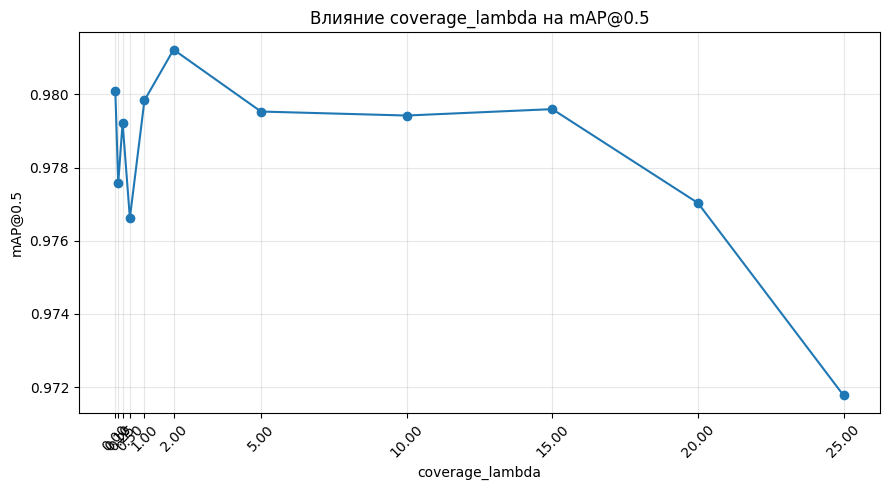

График сохранён: train_result_new_data/coverage_grid/coverage_lambda_map50.png


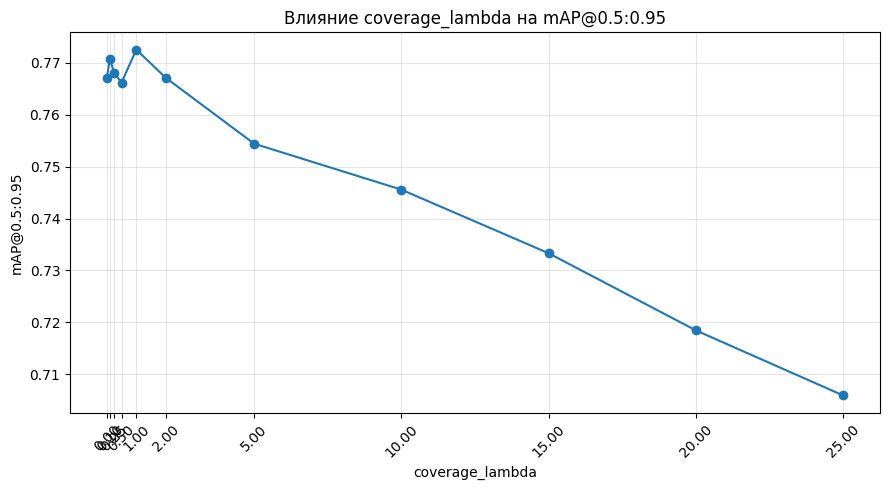

График сохранён: train_result_new_data/coverage_grid/coverage_lambda_map50_95.png


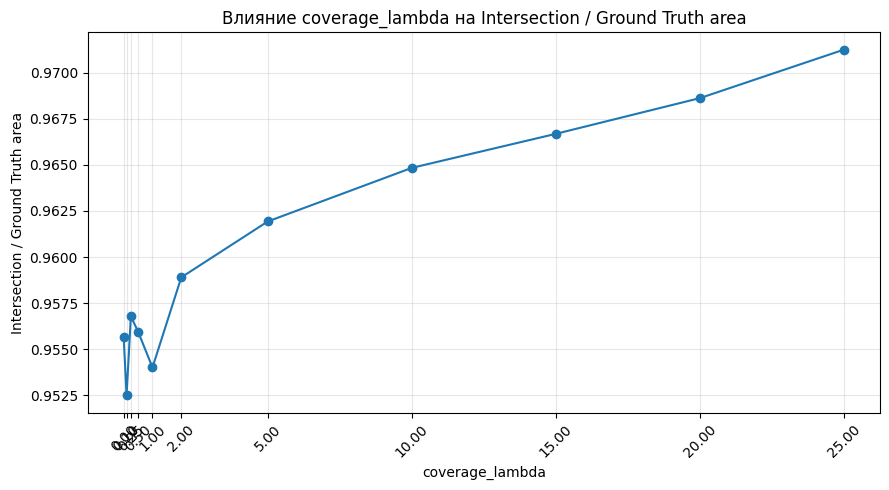

График сохранён: train_result_new_data/coverage_grid/coverage_lambda_intersection_gt.png


In [37]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from pathlib import Path

# Загружаем сохранённые результаты, если ядро перезапускалось
results_file = GRID_OUTPUT_DIR / "coverage_grid_results.csv"

results_df = pd.read_csv(results_file)

successful = results_df[
    (results_df["status"] == "success")
].copy()

successful = successful.sort_values("coverage_lambda")

if successful.empty:
    raise ValueError(
        "Нет успешных экспериментов. Проверьте ошибки обучения."
    )

successful["coverage_lambda"] = pd.to_numeric(
    successful["coverage_lambda"]
)

plots = [
    (
        "mAP50",
        "mAP@0.5",
        "coverage_lambda_map50.png",
    ),
    (
        "mAP50-95",
        "mAP@0.5:0.95",
        "coverage_lambda_map50_95.png",
    ),
    (
        "Intersection/GT",
        "Intersection / Ground Truth area",
        "coverage_lambda_intersection_gt.png",
    ),
]

for metric_col, ylabel, filename in plots:

    data = successful.dropna(subset=[metric_col])

    plt.figure(figsize=(9, 5))

    plt.plot(
        data["coverage_lambda"],
        data[metric_col],
        marker="o",
    )

    plt.xlabel("coverage_lambda")
    plt.ylabel(ylabel)
    plt.title(f"Влияние coverage_lambda на {ylabel}")
    plt.grid(True, alpha=0.3)
    plt.xticks(data["coverage_lambda"], rotation=45)
    plt.tight_layout()

    save_path = GRID_OUTPUT_DIR / filename
    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

    print("График сохранён:", save_path)

In [39]:
visualize_predictions_vs_gt(
    'coverage_grid/coverage_lambda_25_0',
    RESULTS_DIR,
    DATA_YAML,
    num_samples=400,
    conf_threshold=0.3,
    iou_threshold=0.4,
    img_size=640,
    seed=42
)

new_block_detection-2/valid/images
Обработка 1/11: vid0499img1290_1_0_jpg.rf.59b9909ce55a9c1e8168e2d1ee2692f1.jpg
  Сохранено: comparison_001_vid0499img1290_1_0_jpg.rf.59b9909ce55a9c1e8168e2d1ee2692f1.jpg
  GT: 5 объектов, Predictions: 15 объектов

Обработка 2/11: vid0489img30_4_1_jpg.rf.aca42f6e41026a1b4bd32ef6a78d28c5.jpg
  Сохранено: comparison_002_vid0489img30_4_1_jpg.rf.aca42f6e41026a1b4bd32ef6a78d28c5.jpg
  GT: 36 объектов, Predictions: 63 объектов

Обработка 3/11: vid0489img2250_4_0_jpg.rf.453d246b437d688264d264b99e30a23b.jpg
  Сохранено: comparison_003_vid0489img2250_4_0_jpg.rf.453d246b437d688264d264b99e30a23b.jpg
  GT: 18 объектов, Predictions: 34 объектов

Обработка 4/11: vid0489img30_4_0_jpg.rf.5c211fe4579a2f8d27f91d5753fb1398.jpg
  Сохранено: comparison_004_vid0489img30_4_0_jpg.rf.5c211fe4579a2f8d27f91d5753fb1398.jpg
  GT: 28 объектов, Predictions: 56 объектов

Обработка 5/11: vid0499img1200_3_0_jpg.rf.9972bb714676db1a9d62d8f25325476b.jpg
  Сохранено: comparison_005_vid0499

'./train_result_new_data/coverage_grid/coverage_lambda_25_0/val/res'

In [40]:
visualize_predictions_vs_gt(
    'coverage_grid/coverage_lambda_25_0',
    RESULTS_DIR,
    'block-detection-1/data.yaml',
    num_samples=400,
    conf_threshold=0.3,
    iou_threshold=0.4,
    img_size=640,
    seed=42
)

block-detection-1/valid/images
Обработка 1/123: 6fbc3bab88742020120b48e272915d25_jpg.rf.51c474a8809d18bf99787cd15a510aaf.jpg
  Сохранено: comparison_001_6fbc3bab88742020120b48e272915d25_jpg.rf.51c474a8809d18bf99787cd15a510aaf.jpg
  GT: 24 объектов, Predictions: 24 объектов

Обработка 2/123: artworks-000022313743-yn12zz-t500x500_jpg.rf.e28a4b4000ee8c019097a5f70d977bd5.jpg
  Сохранено: comparison_002_artworks-000022313743-yn12zz-t500x500_jpg.rf.e28a4b4000ee8c019097a5f70d977bd5.jpg
  GT: 36 объектов, Predictions: 36 объектов

Обработка 3/123: wall-brick-red-brick-500x500-2-_jpg.rf.75939b79af1bc9181475619f8f737cdd.jpg
  Сохранено: comparison_003_wall-brick-red-brick-500x500-2-_jpg.rf.75939b79af1bc9181475619f8f737cdd.jpg
  GT: 40 объектов, Predictions: 40 объектов

Обработка 4/123: 4_jpg.rf.7e70007b71984be56478ff363b8d6906.jpg
  Сохранено: comparison_004_4_jpg.rf.7e70007b71984be56478ff363b8d6906.jpg
  GT: 104 объектов, Predictions: 104 объектов

Обработка 5/123: _barhat-2-500x500-500x500_jp

'./train_result_new_data/coverage_grid/coverage_lambda_25_0/val/res'